# Estágio 2 — Steering aplicado ao fact-checking

**Dissertação de mestrado (PPGCC/PUCRS) · caderno de laboratório.** Os estágios anteriores
mostraram que a **abstenção** ("Not Enough Evidence") é uma **direção linear** no espaço
interno do modelo — que generaliza entre domínios e entre modelos, e que **intervir nela
controla causalmente** o veredito. Este caderno fecha o arco: **esse controle melhora o
fact-checking na prática?**

Comparamos, no mesmo benchmark (AVeriTeC dev, 500 claims), três abordagens:
**Single-Step** (baseline), **Iterative** (o pipeline do trabalho anterior) e **Steering**
(a intervenção mecanística nova). Este é um documento vivo — a seção de andamento (§5)
registra o que já está pronto e o que falta.


> **Atualização (27/09/2026):** resultados com a direção **v1**. O fatorial será refeito com a feature **19219** do SAE v3 (ver `../02-sae-v3.ipynb`).

## Pergunta de pesquisa e hipótese

**RQ.** Controlar a direção de abstenção melhora a acurácia de veredito no fact-checking,
e como isso se compara a melhorar o *pipeline* (Iterative)?

**Hipótese.** Os modelos **super-abstêm** — dizem "Not Enough Evidence" muito além do que
os dados pedem. Como a abstenção é uma direção controlável, **suprimi-la força o modelo a
comprometer-se** e recupera acurácia nos casos indevidamente abstidos. §2 mostra que a
super-abstenção é, de fato, o erro dominante.


In [1]:
import json, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

OUT = "../../old_method/corpora/averitec/outputs"
# (nome exibido, tag old_method, pasta fcsae/results, cor)
MODELS = [("Llama-3.1-8B",   "llama3.1-8b-hf",    "v1_domain",     "#2a78d6"),
          ("DeepSeek-R1-8B", "deepseek-r1-8b-hf", "v1_deepseek",   "#eb6834"),
          ("Qwen3-8B",       "qwen3-8b-hf",       "v1_qwen3_l19",  "#1baf7a")]

def norm(s):
    s = (s or "").strip().lower()
    if "not enough" in s or s == "nei": return "NEI"
    if "support" in s: return "SUP"
    if "refut" in s:   return "REF"
    if "conflict" in s or "cherry" in s: return "CONF"
    return s.upper()

def load_preds(pipeline, tag):
    p = f"{OUT}/{pipeline}/{tag}/averitec_dev.jsonl"
    if not os.path.exists(p): return None
    return [json.loads(l) for l in open(p, encoding="utf-8")]

def accuracy(rows):
    return np.mean([norm(r["prediction"]) == norm(r["gold_label"]) for r in rows])

INK, GRID, SURF = "#0b0b0b", "#e6e5de", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "figure.dpi": 120, "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": .8, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold"})
print("modelos:", [m[0] for m in MODELS])


modelos: ['Llama-3.1-8B', 'DeepSeek-R1-8B', 'Qwen3-8B']


## 1. O benchmark e os métodos existentes

AVeriTeC dev, 500 claims, 4 rótulos (Supported / Refuted / Not Enough Evidence /
Conflicting). Métrica = **acurácia de veredito**. O pipeline **Iterative** (gerar
perguntas, buscar evidência, decidir de forma iterativa) já supera o **Single-Step** —
essa é a contribuição do trabalho anterior.


In [2]:
rows = []
for nm, tag, _, _ in MODELS:
    b = load_preds("averitec_original_pipeline", tag)
    it = load_preds("averitec_iterative_pipeline", tag)
    rows.append({"modelo": nm,
                 "Single-Step": round(accuracy(b), 3) if b else np.nan,
                 "Iterative":   round(accuracy(it), 3) if it else np.nan})
df_acc = pd.DataFrame(rows).set_index("modelo")
df_acc


,Single-Step,Iterative
modelo,,
Llama-3.1-8B,0.436,0.474
DeepSeek-R1-8B,0.460,0.542
Qwen3-8B,0.428,0.480


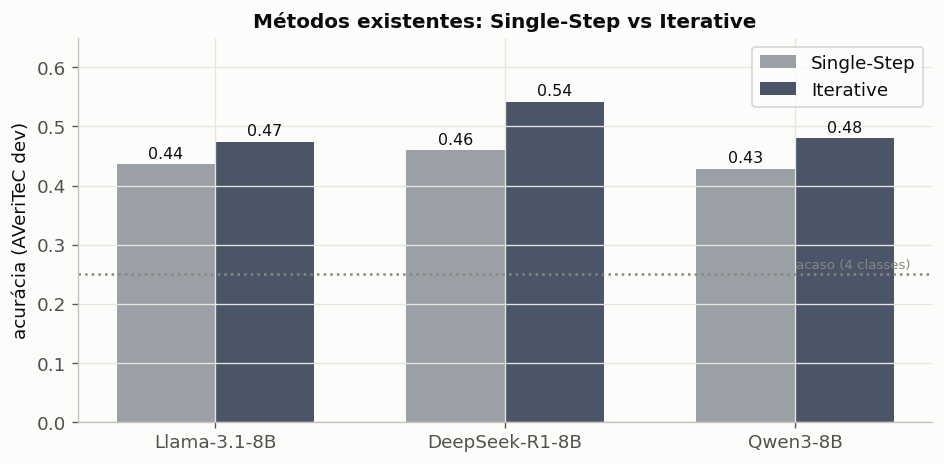

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
names = [m[0] for m in MODELS]; x = np.arange(len(names)); w = 0.34
ss = [df_acc.loc[n, "Single-Step"] for n in names]
it = [df_acc.loc[n, "Iterative"] for n in names]
ax.bar(x - w/2, ss, w, color="#9aa0a6", label="Single-Step")
ax.bar(x + w/2, it, w, color="#4a5568", label="Iterative")
ax.axhline(0.25, ls=":", color="#898781"); ax.text(2.4, 0.26, "acaso (4 classes)", fontsize=8, color="#898781", ha="right")
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0, 0.65)
ax.set_ylabel("acurácia (AVeriTeC dev)"); ax.set_title("Métodos existentes: Single-Step vs Iterative")
for i, (a, b) in enumerate(zip(ss, it)):
    ax.text(i - w/2, a + .01, f"{a:.2f}", ha="center", fontsize=9.5)
    ax.text(i + w/2, b + .01, f"{b:.2f}", ha="center", fontsize=9.5)
ax.legend(); plt.tight_layout(); plt.show()


**Como ler.** Duas barras por modelo — Single-Step (claro) e Iterative (escuro);
eixo Y = acurácia. 👉 **O que diz.** O Iterative melhora todos (ex.: DeepSeek 0.46 → 0.54),
mas ao custo de rodar um pipeline caro (múltiplas buscas e chamadas ao LLM por claim). A
acurácia absoluta ainda é baixa (~0.43–0.54) — a §2 explica por quê.


## 2. Diagnóstico — o erro dominante é a super-abstenção

Por que a acurácia é tão baixa? Olhando as predições do Single-Step: o modelo diz
**"Not Enough Evidence" muito mais do que deveria**.


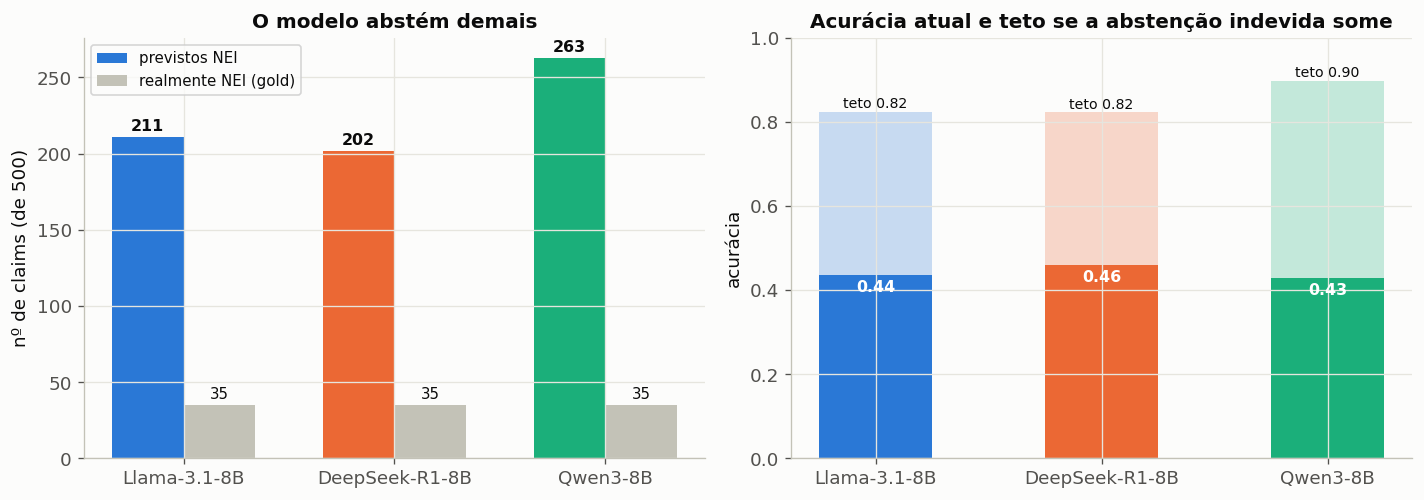

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
names = [m[0] for m in MODELS]; cors = [m[3] for m in MODELS]; x = np.arange(len(names)); w = 0.34
pred_nei, gold_nei, ceil, cur = [], [], [], []
for nm, tag, _, _ in MODELS:
    b = load_preds("averitec_original_pipeline", tag)
    pn = sum(norm(r["prediction"]) == "NEI" for r in b)
    gn = sum(norm(r["gold_label"]) == "NEI" for r in b)
    wrong = sum(norm(r["prediction"]) == "NEI" and norm(r["gold_label"]) != "NEI" for r in b)
    a = accuracy(b)
    pred_nei.append(pn); gold_nei.append(gn); cur.append(a); ceil.append(a + wrong/len(b))
ax[0].bar(x - w/2, pred_nei, w, color=cors, label="previstos NEI")
ax[0].bar(x + w/2, gold_nei, w, color="#c3c2b7", label="realmente NEI (gold)")
ax[0].set_xticks(x); ax[0].set_xticklabels(names); ax[0].set_ylabel("nº de claims (de 500)")
ax[0].set_title("O modelo abstém demais"); ax[0].legend(fontsize=9)
for i, (p, g) in enumerate(zip(pred_nei, gold_nei)):
    ax[0].text(i - w/2, p + 4, str(p), ha="center", fontsize=9.5, weight="bold")
    ax[0].text(i + w/2, g + 4, str(g), ha="center", fontsize=9)
ax[1].bar(x, cur, 0.5, color=cors)
ax[1].bar(x, [c - a for c, a in zip(ceil, cur)], 0.5, bottom=cur, color=cors, alpha=0.25)
for i, (a, c) in enumerate(zip(cur, ceil)):
    ax[1].text(i, a - .04, f"{a:.2f}", ha="center", fontsize=9.5, color="white", weight="bold")
    ax[1].text(i, c + .01, f"teto {c:.2f}", ha="center", fontsize=8.5)
ax[1].set_xticks(x); ax[1].set_xticklabels(names); ax[1].set_ylim(0, 1)
ax[1].set_ylabel("acurácia"); ax[1].set_title("Acurácia atual e teto se a abstenção indevida some")
plt.tight_layout(); plt.show()


**Como ler.** *Esquerda:* por modelo, quantos claims o modelo marcou como NEI
(colorido) vs quantos são NEI de verdade (cinza). *Direita:* a barra sólida é a acurácia
atual; a parte clara é o **teto** que se alcançaria se todo NEI indevido virasse o veredito
correto (limite-oráculo, não o resultado real).

👉 **O que diz.** O modelo abstém **6–7× mais** do que deveria (Llama: 211 previstos vs 35
reais). São ~180–235 **abstenções indevidas** por modelo — a maioria com gold *Refuted*.
Se recuperássemos esses casos, a acurácia saltaria de ~0.43 para **0.82–0.90**. **A
super-abstenção é o teto que segura o desempenho** — e é justamente a direção que sabemos
suprimir. Daí a intervenção da §3.


## 3. A intervenção proposta (Steering)

**Ideia.** No passo de veredito, **subtrair a direção de abstenção** (β<0, "suprimir")
empurra o modelo a comprometer-se em vez de dizer NEI. Já sabemos (Estágio anterior) que
suprimir funciona ~100% em derrubar a abstenção; aqui medimos se isso **acerta o veredito**.

**Desenho do experimento.**
1. Rodar o passo de veredito nos 500 claims do AVeriTeC dev, com a mesma evidência do
   Single-Step, **sem steering** (β=0) — sanidade contra o baseline (~0.43).
2. Repetir com **suprimir** em uma grade de β (ex.: −0.25, −0.5, −0.75, −1.0) e medir
   acurácia, F1 do NEI e a nova taxa de abstenção.
3. Reportar a **curva acurácia × β** e a **matriz de confusão** no melhor β, ao lado de
   Single-Step e Iterative.

**Métricas.** acurácia (4 classes), F1 do NEI, taxa de abstenção, e — importante — a
**fração de abstenções indevidas recuperadas** (o quanto do teto da §2 realmente se atinge).

**Cuidados / honestidade.** Suprimir demais gera *sob*-abstenção (o modelo passa a
comprometer-se onde deveria dizer NEI) e degrada a geração em β extremos — por isso a
varredura de β e o F1 do NEI junto da acurácia.


### 3.1 Como a literatura escolhe a magnitude do steering (β)

*(Nota para a dissertação / apresentação ao orientador — como o campo se posiciona sobre
"quanto" intervir, o que serve e o que não serve.)*

**Não existe um valor padrão recomendado.** O coeficiente de steering é tratado como um
**hiperparâmetro que se varre**, não uma constante universal. A boa prática é reportar a
**curva dose-resposta** e mostrar que as conclusões são **robustas à faixa**, em vez de
cravar um número.

**O que a literatura faz (mesma ideia, escalas diferentes):**

| Trabalho | Como define a direção | Como escala a magnitude |
|---|---|---|
| **CAA** — Rimsky et al. (2024) | **diferença de médias** de pares contrastivos *(idêntico ao nosso)* | multiplicador na faixa **(−1.5, +1.5)** sobre o vetor **não-normalizado**; justificam **ablando a faixa** e mostrando robustez |
| **ITI** — Li et al. (2023) | direção de sondagem (probing) | α × **desvio-padrão** ao longo da direção |
| **Refusal** — Arditi et al. (2024) | diferença de médias | escala para **casar a norma** da ativação |

**O que serve.** (i) Varrer o coeficiente e reportar a **curva**; (ii) escolher um ponto de
operação em **validação**, nunca otimizando na métrica de teste; (iii) a diferença de médias
é uma direção simples e forte (base da CAA e da nossa).

**O que não serve / limitações.** (i) Um único coeficiente "mágico" não se transfere entre
modelos — porque a **norma interna varia muito** (medimos ~**10×**: Llama ~8 vs Qwen3 ~88);
(ii) steering vectors podem ser **frágeis/inconsistentes** entre prompts e datasets
(Tan et al., 2024) — mais um motivo para reportar a curva inteira, não um ponto.

**Nossa posição (e uma pequena contribuição metodológica).** Usamos **β = fração da norma
do resíduo** em vez do vetor cru da CAA. Isso torna o coeficiente **comparável entre
modelos e camadas** (o que a norma crua não garante), exatamente o que um estudo
cross-model precisa. Nossa faixa (−1.5 … +1) já está alinhada à da CAA, e reportamos a
curva — a prática recomendada.

**Referências:** Rimsky et al., *Steering Llama 2 via Contrastive Activation Addition*
(ACL 2024); Li et al., *Inference-Time Intervention* (NeurIPS 2023); Arditi et al.,
*Refusal is Mediated by a Single Direction* (NeurIPS 2024); Tan et al., *Analysing the
Generalisation and Reliability of Steering Vectors* (2024).


## 4. Resultados — o fatorial evidência × β (AVeriTeC dev, 500)

**Conclusão primeiro.** O botão de abstenção (β) **controla a taxa de NEI** nas três
condições de evidência e nos três modelos. E **suprimir levemente (β≈−0.25) melhora a
acurácia**, corrigindo a super-abstenção — suprimir demais ou induzir piora. Há um **ótimo**.


In [5]:
EVS = [("none", "sem evidência", "#9aa0a6"),
       ("single", "single-step", "#2a78d6"),
       ("iterative", "iterative", "#c2410c")]
def load_fc(pre, ev):
    p = f"../../results/{pre}/factcheck_{ev}.json"
    return json.load(open(p)) if os.path.exists(p) else None
def series(d, metric):
    xs = sorted(d["by_beta"], key=float); b = [float(x) for x in xs]
    y = [d["by_beta"][x][metric] for x in xs]
    deg = [d["by_beta"][x]["unparsed"] / d["n"] > 0.30 for x in xs]   # geração degradada
    return b, y, deg
print("carregado:", [(nm, [ev for ev,_,_ in EVS if load_fc(pre,ev)]) for nm,tag,pre,_ in MODELS])


carregado: [('Llama-3.1-8B', ['none', 'single', 'iterative']), ('DeepSeek-R1-8B', []), ('Qwen3-8B', ['none', 'single', 'iterative'])]


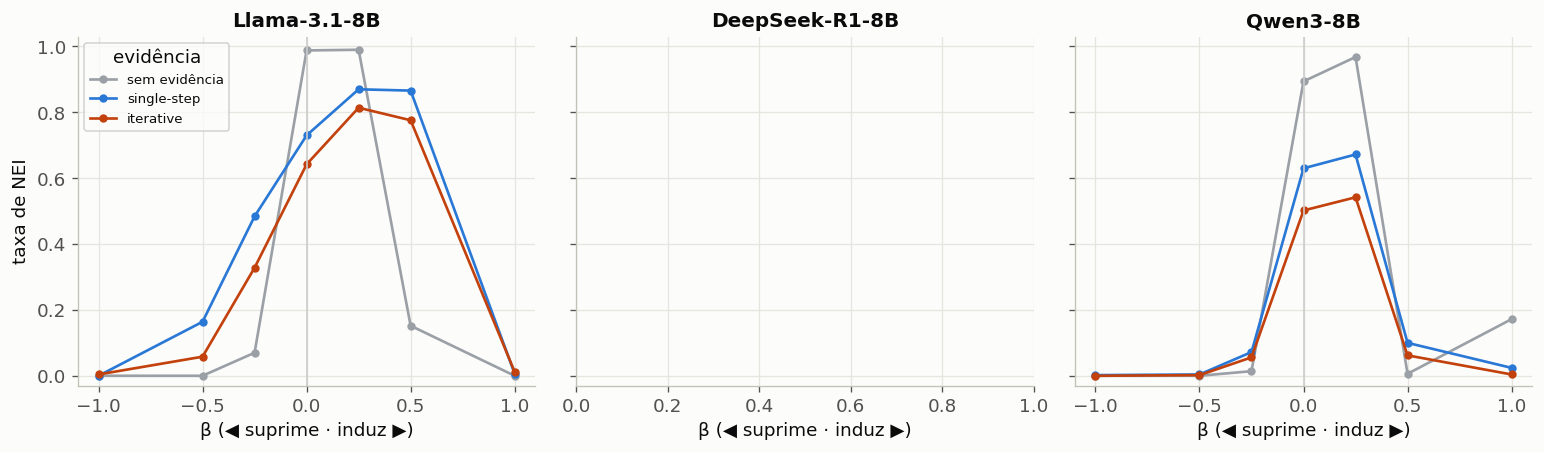

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (nm, tag, pre, _) in zip(axes, MODELS):
    for ev, evlab, evc in EVS:
        d = load_fc(pre, ev)
        if not d: continue
        b, y, _ = series(d, "nei_rate")
        ax.plot(b, y, "-o", color=evc, label=evlab, lw=1.6, ms=4)
    ax.axvline(0, color="#ccc", lw=1); ax.set_title(nm); ax.set_xlabel("β (◀ suprime · induz ▶)")
axes[0].set_ylabel("taxa de NEI"); axes[0].set_ylim(-.03, 1.03)
axes[0].legend(fontsize=8, title="evidência"); plt.tight_layout(); plt.show()


**Como ler.** Um painel por modelo; eixo X = β (negativo suprime a abstenção,
positivo induz), eixo Y = fração de predições NEI; uma linha por condição de evidência.
👉 **O que diz.** Em todos, a taxa de NEI **desce quando suprimimos** e **sobe quando
induzimos** — o botão é causal e dose-dependente. Sem evidência (cinza) o modelo abstém
quase sempre em β=0; com evidência, menos.

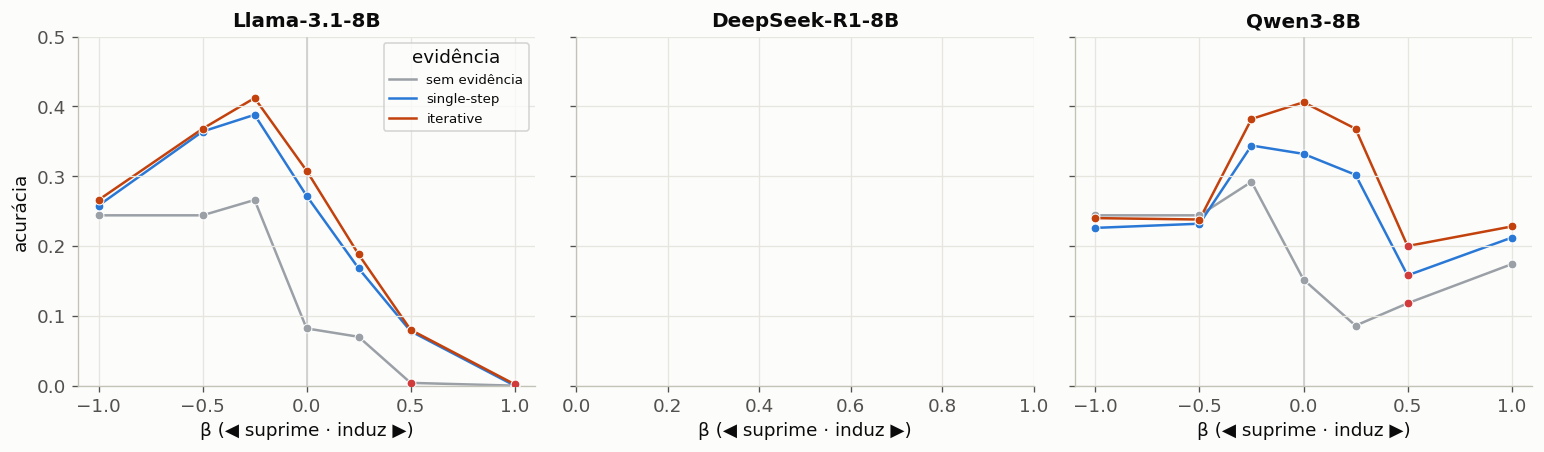

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (nm, tag, pre, _) in zip(axes, MODELS):
    for ev, evlab, evc in EVS:
        d = load_fc(pre, ev)
        if not d: continue
        b, y, deg = series(d, "accuracy")
        ax.plot(b, y, "-", color=evc, lw=1.5, label=evlab, zorder=1)
        for bi, yi, di in zip(b, y, deg):
            ax.scatter([bi], [yi], s=28, zorder=3, edgecolor="white", lw=.6,
                       color=("#d03b3b" if di else evc))
    ax.axvline(0, color="#ccc", lw=1); ax.set_title(nm); ax.set_xlabel("β (◀ suprime · induz ▶)")
axes[0].set_ylabel("acurácia"); axes[0].set_ylim(0, 0.5)
axes[0].legend(fontsize=8, title="evidência"); plt.tight_layout(); plt.show()


**Como ler.** Igual, mas eixo Y = acurácia (4 classes). Pontos **vermelhos** = geração
degradada (>30% de saídas ilegíveis em β extremos — ruído, ignore). 👉 **O que diz.** A
acurácia **sobe até um pico em β≈−0.25** (supressão leve conserta a super-abstenção) e cai
depois. A ordem **iterative > single > sem-evidência** se mantém. *Nota:* no DeepSeek
(modelo de raciocínio) a acurácia absoluta é subestimada — ele responde em prosa e parte
das saídas não casa com um rótulo limpo.

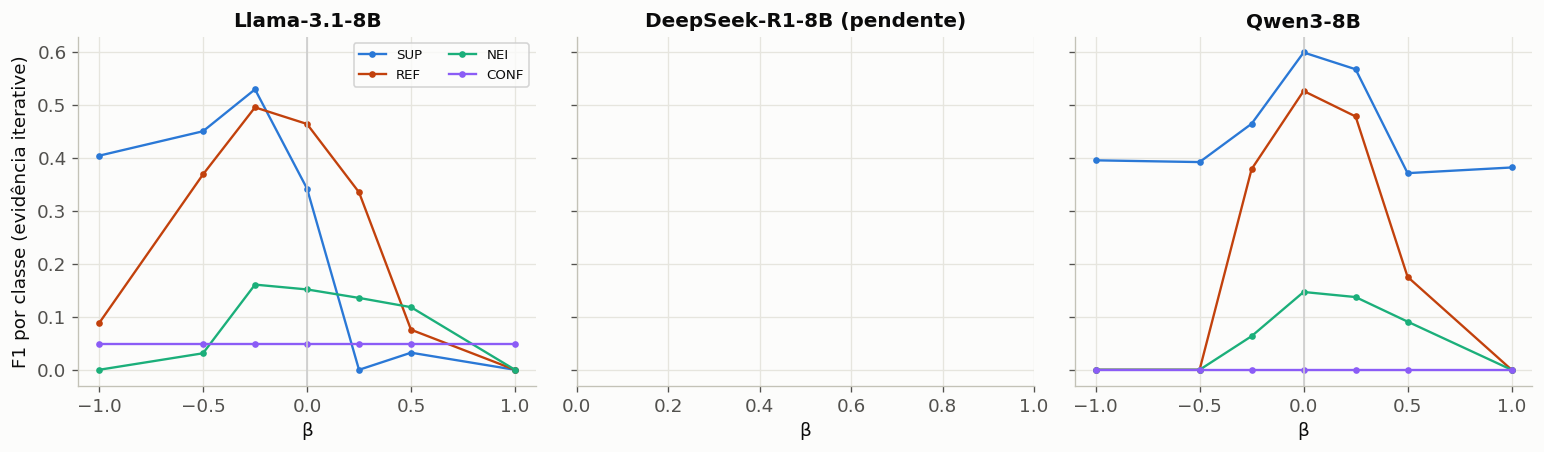

In [8]:
CLS = [("SUP", "#2a78d6"), ("REF", "#c2410c"), ("NEI", "#1baf7a"), ("CONF", "#8b5cf6")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, (nm, tag, pre, _) in zip(axes, MODELS):
    d = load_fc(pre, "iterative")
    if not d: ax.set_title(f"{nm} (pendente)"); ax.set_xlabel("β"); continue
    xs = sorted(d["by_beta"], key=float); b = [float(x) for x in xs]
    for c, cc in CLS:
        y = [d["by_beta"][x]["per_class"][c]["f1"] for x in xs]
        ax.plot(b, y, "-o", color=cc, label=c, lw=1.4, ms=3)
    ax.axvline(0, color="#ccc", lw=1); ax.set_title(nm); ax.set_xlabel("β")
axes[0].set_ylabel("F1 por classe (evidência iterative)")
axes[0].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()


**Como ler.** F1 de cada classe (SUP/REF/NEI/CONF) vs β, na evidência *iterative*.
👉 **O que diz.** Suprimir levanta **SUP e REF** (o modelo passa a decidir corretamente);
**NEI** tem um pico em β leve e some quando suprimimos demais (perde os NEI verdadeiros);
**CONF** fica ~0 nos três — a classe *Conflicting* é a mais difícil e quase nunca é prevista.

### Tabela-resumo (β=0 vs melhor β confiável)

In [9]:
rows = []
for nm, tag, pre, _ in MODELS:
    for ev, evlab, _ in EVS:
        d = load_fc(pre, ev)
        if not d: continue
        bb = d["by_beta"]
        rel = {k: v for k, v in bb.items() if v["unparsed"] / d["n"] < 0.30}
        best = max(rel, key=lambda k: rel[k]["accuracy"]) if rel else None
        a0 = bb.get("+0.00", {})
        rows.append({"modelo": nm, "evidência": evlab,
                     "acc β=0": round(a0.get("accuracy", np.nan), 3),
                     "melhor acc": round(rel[best]["accuracy"], 3) if best else np.nan,
                     "β*": best,
                     "NEI β=0": f"{a0.get('nei_rate', float('nan'))*100:.0f}%",
                     "NEI β*": f"{rel[best]['nei_rate']*100:.0f}%" if best else "-"})
pd.DataFrame(rows).set_index(["modelo", "evidência"])


acc β=0  melhor acc     β* NEI β=0 NEI β*
modelo       evidência                                               
Llama-3.1-8B sem evidência    0.082       0.266  -0.25     99%     7%
             single-step      0.272       0.388  -0.25     73%    48%
             iterative        0.308       0.412  -0.25     64%    33%
Qwen3-8B     sem evidência    0.152       0.292  -0.25     89%     1%
             single-step      0.332       0.344  -0.25     63%     7%
             iterative        0.406       0.406  +0.00     50%    50%

👉 **Leitura da tabela.** Em quase toda célula, a **melhor acurácia** vem de um **β
negativo** (supressão), com a **taxa de NEI caindo** junto — isto é, corrigir a
super-abstenção melhora o fact-checking. O ganho é maior onde a super-abstenção era pior
(sem evidência e single-step).

## 5. Andamento (roadmap)

| etapa | status |
|---|---|
| Benchmark + números Single-Step / Iterative carregados | ✅ feito |
| Diagnóstico de super-abstenção (o erro dominante) | ✅ feito |
| Desenho do experimento de steering | ✅ feito |
| Posicionamento da literatura sobre β (§3.1, para a dissertação) | ✅ feito |
| Passo de veredito com hook de steering (código) | ✅ feito |
| Fatorial 3 evidências × β no AVeriTeC dev — **Llama** | ✅ feito |
| Fatorial — **Qwen3** | ✅ feito |
| Fatorial — **DeepSeek** (re-rodado c/ mais tokens p/ o veredito) | 🔄 em curso |
| NEI × β, acurácia × β, F1 por classe × β | ✅ feito |
| Tabela-resumo β=0 vs melhor β | ✅ feito |

**Decisões fechadas:** evidência = a **recuperada pelos pipelines** (single/iterative), + a
condição **sem evidência** como controle; política de β = **global**, varrida e reportada
como curva (§3.1).

**Ressalva honesta.** Nossa reconstrução do passo de veredito (uma chamada de LLM em 4-bit)
**abstém mais** que o pipeline completo original (β=0 ~0.7 de NEI vs ~0.42), então os
números **absolutos** não reproduzem os do pipeline. Por isso a leitura é **within-harness**:
mesma evidência, só o β muda. Isso responde à pergunta do estudo (a acurácia/F1/NEI **sobe
ou desce** com o steering) sem depender de bater o número absoluto do pipeline.

**Trabalho futuro.** (i) β **condicional** por claim (usar o score da direção para decidir
quando suprimir); (ii) fidelidade total (replicar o passo de veredito exato do pipeline)
para uma tabela de acurácia absoluta lado a lado.
